# Part 4: Mã hóa biến phân loại và chuẩn hóa đặc trưng (Encoding & Normalization)
**Thành viên phụ trách:** Thành viên 4 | **Nhánh Git:** `feature/encoding-normalization` | **Mã nguồn:** `modeling/encoding.py`

---
Notebook thực hiện **và kiểm định** quy trình tiền xử lý đặc trưng trước khi huấn luyện mô hình:

| # | Việc làm | Kiểm định đi kèm |
| :-: | :--- | :--- |
| 1 | Nạp `flights_features.csv` (đầu ra của Part 3), kiểm tra cột và tỷ lệ thiếu | Có đủ 29 cột đầu vào |
| 2 | Chia Train/Test **theo thời gian**, fit bộ tiền xử lý **chỉ trên Train** | `scaler.n_samples_seen_ == số dòng Train` |
| 3 | Cô lập rò rỉ: `delay_min`, `actual_time`, `status`, `status_detail` không được ảnh hưởng tới X | Xáo trộn các cột rò rỉ thì X không đổi |
| 4 | One-Hot cho 5 biến phân loại (`handle_unknown="ignore"`) | Mỗi biến có đúng một cột bằng 1 |
| 5 | StandardScaler cho 10 biến liên tục | Train: trung bình 0, độ lệch chuẩn 1; Test: không đúng 0 |
| 6 | Giữ nguyên 14 cờ nhị phân | Giá trị chỉ là 0 hoặc 1 |
| 7 | Giá trị thiếu: điền **trung vị của Train**; danh mục lạ: vector 0 | Không còn NaN, không crash |
| 8 | Lưu `encoder.joblib`, `scaler.joblib`, `preprocessing_metadata.json` | Nạp lại cho kết quả giống hệt |

> **Phân công:** việc huấn luyện mô hình thuộc Thành viên 5. Notebook này chỉ dùng `split_by_date()` để **fit đúng trên Train**, vì fit trên toàn bộ dữ liệu sẽ làm rò thống kê của tập Test vào bộ chuẩn hóa.

**Cách chạy:** mở notebook trong dự án (cwd là thư mục gốc hoặc `notebooks/`), cần có `data/processed/flights_features.csv` (do Thành viên 3 sinh ra bằng `python main.py features`). Ô ở mục 8 **ghi đè** 3 tệp artifact trong `data/processed/`; đặt `SAVE_ARTIFACTS = False` nếu chỉ muốn xem.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

ROOT = Path.cwd()
if not (ROOT / "config.py").exists() and (ROOT.parent / "config.py").exists():
    ROOT = ROOT.parent                      # notebook đặt trong notebooks/
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from modeling.encoding import (
    CATEGORICAL_COLS, FEATURE_INPUT_COLS, LABEL_MAP, LEAKAGE_COLUMNS, NUMERIC_CONTINUOUS_COLS,
    PASSTHROUGH_BINARY_COLS, PROCESSED_DIR, FlightDataPreprocessor, assert_no_leakage, split_by_date,
)

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

SAVE_ARTIFACTS = True        # False: chỉ xem, không ghi đè artifact
FEATURES_PATH = PROCESSED_DIR / "flights_features.csv"
print(f"Thư mục dự án: {ROOT} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")
assert FEATURES_PATH.exists(), f"Thiếu {FEATURES_PATH}. Nhờ Thành viên 3 chạy: python main.py features"

Thư mục dự án: c:\Users\LENOVO\Documents\ScrapeData | scikit-learn 1.9.1 | pandas 3.0.6


## 1. Dữ liệu đầu vào
Đầu vào là `flights_features.csv` (đầu ra của Part 3). Bộ tiền xử lý dùng **29 cột**: 5 biến phân loại, 10 biến liên tục và 14 cờ nhị phân. Các cột còn lại là định danh, nhãn đích hoặc cột rò rỉ, **không** đi vào ma trận X.

In [2]:
df = pd.read_csv(FEATURES_PATH)
print(f"Dữ liệu đầu vào: {df.shape[0]:,} dòng x {df.shape[1]} cột")

missing_cols = [c for c in FEATURE_INPUT_COLS if c not in df.columns]
assert not missing_cols, f"Thiếu cột đặc trưng đầu vào: {missing_cols}"

groups = pd.DataFrame([
    ("Phân loại (One-Hot)", len(CATEGORICAL_COLS), ", ".join(CATEGORICAL_COLS)),
    ("Liên tục (StandardScaler)", len(NUMERIC_CONTINUOUS_COLS), ", ".join(NUMERIC_CONTINUOUS_COLS)),
    ("Nhị phân (giữ nguyên)", len(PASSTHROUGH_BINARY_COLS), ", ".join(PASSTHROUGH_BINARY_COLS)),
    ("Rò rỉ (bị loại khỏi X)", len(LEAKAGE_COLUMNS), ", ".join(LEAKAGE_COLUMNS)),
], columns=["Nhóm", "Số cột", "Các cột"])
display(groups)

miss = (df[FEATURE_INPUT_COLS].isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print("Tỷ lệ thiếu (%) của các cột đầu vào có giá trị thiếu (căn cứ chọn cách điền):")
display(miss.to_frame("% thiếu").T if len(miss) else "Không có cột nào thiếu giá trị")
print("\nPhân bố nhãn đích status_clean:")
display(df["status_clean"].value_counts().to_frame("Số chuyến").join(
    (df["status_clean"].value_counts(normalize=True) * 100).round(1).rename("%")))

Dữ liệu đầu vào: 13,965 dòng x 47 cột


,Nhóm,Số cột,Các cột
0,Phân loại (One-Hot),5,"airline_code, airport, direction, route_type, ..."
1,Liên tục (StandardScaler),10,"airport_load, precipitation, wind_gusts_10m, v..."
2,Nhị phân (giữ nguyên),14,"is_peak_hour, is_heavy_traffic, is_rain, is_he..."
3,Rò rỉ (bị loại khỏi X),5,"delay_min, actual_time, status, status_detail,..."


Tỷ lệ thiếu (%) của các cột đầu vào có giá trị thiếu (căn cứ chọn cách điền):


,airport_load,precipitation,wind_gusts_10m,visibility
% thiếu,0.35,0.35,0.35,0.35



Phân bố nhãn đích status_clean:


,Số chuyến,%
status_clean,,
on_time,9960,71.3
delayed,3886,27.8
cancelled,119,0.9


## 2. Chia theo thời gian và fit chỉ trên Train
**Vì sao fit chỉ trên Train:** trung bình, độ lệch chuẩn, trung vị và tập danh mục đều là thông tin học từ dữ liệu. Nếu tính trên cả Test, thông tin "tương lai" lọt vào bước tiền xử lý (rò rỉ gián tiếp). Chia theo thời gian (không shuffle): 80% ngày đầu làm Train, 20% ngày sau làm Test.

In [3]:
clean = df[df["status_clean"].isin(LABEL_MAP)].copy()
train_raw, test_raw, cutoff = split_by_date(clean, train_ratio=0.80)

pre = FlightDataPreprocessor().fit(train_raw)            # CHỈ fit trên Train
X_train = pre.to_dataframe(pre.transform(train_raw))
X_test = pre.to_dataframe(pre.transform(test_raw))

split_info = pd.DataFrame({
    "Số dòng": [len(train_raw), len(test_raw)],
    "Ngày đầu": [train_raw["flight_date"].min(), test_raw["flight_date"].min()],
    "Ngày cuối": [train_raw["flight_date"].max(), test_raw["flight_date"].max()],
    "% on_time": [(s["status_clean"] == "on_time").mean() * 100 for s in (train_raw, test_raw)],
    "% delayed": [(s["status_clean"] == "delayed").mean() * 100 for s in (train_raw, test_raw)],
    "% cancelled": [(s["status_clean"] == "cancelled").mean() * 100 for s in (train_raw, test_raw)],
}, index=["Train", "Test"]).round(1)
display(split_info)
print(f"Mốc cắt (ngày cuối của Train): {cutoff}")
if test_raw["flight_date"].min() == cutoff:
    print("Lưu ý: ngày cắt xuất hiện ở cả hai tập (cắt giữa ngày, đã sắp xếp theo giờ bay). Chấp nhận được, nhưng cần nêu trong báo cáo.")

assert int(pre.scaler.n_samples_seen_) == len(train_raw), "Scaler không được fit trên toàn bộ dữ liệu!"
assert train_raw["flight_date"].max() <= test_raw["flight_date"].min()
print(f"ĐẠT: scaler được fit trên {int(pre.scaler.n_samples_seen_):,} dòng Train (không có dòng Test), Train kết thúc trước Test.")
print(f"Ma trận đặc trưng: Train {X_train.shape} | Test {X_test.shape}")

,Số dòng,Ngày đầu,Ngày cuối,% on_time,% delayed,% cancelled
Train,11172,2026-10-08,2026-10-31,69.1,29.8,1.0
Test,2793,2026-10-31,2026-11-02,80.0,19.9,0.1


Mốc cắt (ngày cuối của Train): 2026-10-31
Lưu ý: ngày cắt xuất hiện ở cả hai tập (cắt giữa ngày, đã sắp xếp theo giờ bay). Chấp nhận được, nhưng cần nêu trong báo cáo.
ĐẠT: scaler được fit trên 11,172 dòng Train (không có dòng Test), Train kết thúc trước Test.
Ma trận đặc trưng: Train (11172, 64) | Test (2793, 64)


## 3. Kiểm định chống rò rỉ dữ liệu
Kiểm tra "cột rò rỉ không có trong tên cột X" là **chưa đủ** (nó luôn đúng vì X được tạo từ danh sách cột cố định). Hai kiểm định dưới đây chặt hơn:

1. **Cấp mã nguồn:** `assert_no_leakage()` báo lỗi nếu danh sách cột đặc trưng chứa cột rò rỉ hoặc nhãn đích.
2. **Kiểm định nhiễu (perturbation):** xáo trộn ngẫu nhiên các cột rò rỉ có trong dữ liệu (`delay_min`, `actual_time`, `status`, `status_detail`, `is_delayed_for_analysis`) và `status_clean`. Nếu ma trận X **không đổi**, chứng tỏ X không phụ thuộc vào chúng.

In [4]:
assert_no_leakage(FEATURE_INPUT_COLS)
for col in LEAKAGE_COLUMNS + ["status_clean"]:
    assert col not in pre.feature_names, f"Rò rỉ: {col} nằm trong X"
print("ĐẠT (1): không có cột rò rỉ hoặc nhãn trong danh sách đặc trưng.")

shuffled = test_raw.copy()
present = [c for c in LEAKAGE_COLUMNS + ["status_clean"] if c in shuffled.columns]
for c in present:
    shuffled[c] = shuffled[c].sample(frac=1, random_state=42).values
np.testing.assert_array_equal(pre.transform(test_raw), pre.transform(shuffled))
print(f"ĐẠT (2): xáo trộn {len(present)} cột rò rỉ/nhãn ({', '.join(present)}), ma trận X không thay đổi một giá trị nào.")

ĐẠT (1): không có cột rò rỉ hoặc nhãn trong danh sách đặc trưng.
ĐẠT (2): xáo trộn 6 cột rò rỉ/nhãn (delay_min, actual_time, status, status_detail, is_delayed_for_analysis, status_clean), ma trận X không thay đổi một giá trị nào.


## 4. Mã hóa One-Hot cho biến phân loại
Mỗi giá trị của biến phân loại trở thành một cột 0/1. Với `handle_unknown="ignore"`, khi chạy thực tế gặp **hãng hoặc sân bay chưa từng thấy lúc huấn luyện**, bộ mã hóa gán vector toàn 0 cho biến đó thay vì báo lỗi, nên dịch vụ web không bị crash.

In [5]:
rows = []
for name, cats in zip(CATEGORICAL_COLS, pre.encoder.categories_):
    freq = train_raw[name].astype(str).value_counts()
    rare = int((freq / len(train_raw) < 0.01).sum())
    rows.append({"Biến": name, "Số danh mục (Train)": len(cats), "Số cột sau One-Hot": len(cats),
                 "Danh mục phổ biến nhất": f"{freq.index[0]} ({freq.iloc[0] / len(train_raw) * 100:.1f}%)",
                 "Danh mục hiếm (<1%)": rare})
ohe = pd.DataFrame(rows)
display(ohe)

n_cat_cols = int(ohe["Số cột sau One-Hot"].sum())
print(f"5 biến phân loại -> {n_cat_cols} cột One-Hot. Tổng đặc trưng cuối: {len(pre.feature_names)} "
      f"= {n_cat_cols} (One-Hot) + {len(NUMERIC_CONTINUOUS_COLS)} (liên tục) + {len(PASSTHROUGH_BINARY_COLS)} (nhị phân)")

for col in CATEGORICAL_COLS:
    cols = [c for c in pre.encoded_cat_names if c.startswith(col + "_")]
    assert (X_train[cols].sum(axis=1) == 1).all(), f"{col}: mỗi dòng Train phải có đúng một cột bằng 1"
print("ĐẠT: mỗi dòng Train có đúng một cột = 1 cho từng biến phân loại.")
if (ohe["Danh mục hiếm (<1%)"] > 0).any():
    print("Gợi ý: biến có nhiều danh mục hiếm (ví dụ `airport`) có thể gộp danh mục hiếm thành 'OTHER' nếu mô hình bị quá khớp; hiện giữ nguyên theo đặc tả.")

,Biến,Số danh mục (Train),Số cột sau One-Hot,Danh mục phổ biến nhất,Danh mục hiếm (<1%)
0,airline_code,7,7,VN (38.4%),1
1,airport,23,23,SGN (38.7%),18
2,direction,2,2,DEPARTURES (66.5%),0
3,route_type,2,2,domestic (69.9%),0
4,carrier_category,6,6,LCC (39.1%),1


5 biến phân loại -> 40 cột One-Hot. Tổng đặc trưng cuối: 64 = 40 (One-Hot) + 10 (liên tục) + 14 (nhị phân)
ĐẠT: mỗi dòng Train có đúng một cột = 1 cho từng biến phân loại.
Gợi ý: biến có nhiều danh mục hiếm (ví dụ `airport`) có thể gộp danh mục hiếm thành 'OTHER' nếu mô hình bị quá khớp; hiện giữ nguyên theo đặc tả.


## 5. Chuẩn hóa StandardScaler cho biến liên tục
Mỗi biến liên tục được đưa về thang chuẩn:

$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

với $\mu$ và $\sigma$ **tính trên tập Train**. Các thang đo rất khác nhau (tầm nhìn hàng chục nghìn mét, gió vài chục km/h, mưa vài mm) về cùng thang, nên các thuật toán dựa trên khoảng cách hoặc gradient (Logistic Regression, K-Means, PCA) không bị biến có số đo lớn chi phối. Kết quả kỳ vọng: **Train có trung bình 0, độ lệch chuẩn 1; Test lệch nhẹ khỏi 0/1** (điều này là đúng và cho thấy không có rò rỉ thống kê).

,μ Train (gốc),σ Train (gốc),Trung bình Train sau chuẩn hóa,Độ lệch chuẩn Train sau chuẩn hóa,Trung bình Test sau chuẩn hóa,Độ lệch chuẩn Test sau chuẩn hóa
airport_load,25.7159,12.7251,0.0,1.0,0.1942,0.9394
precipitation,0.2777,0.9056,0.0,1.0,-0.1038,0.5368
wind_gusts_10m,18.6317,7.2735,0.0,1.0,0.1567,1.2063
visibility,13679.5650,7362.3263,-0.0,1.0,-0.1259,1.0299
weather_hazard_score,0.0673,0.0973,-0.0,1.0,0.1024,0.7943
load_x_weather,1.5696,2.5238,-0.0,1.0,0.2420,1.0537
hour_sin,-0.2265,0.6955,-0.0,1.0,0.1233,1.0200
hour_cos,-0.2936,0.6154,0.0,1.0,0.1277,1.0664
dow_sin,-0.0427,0.6830,0.0,1.0,-0.8370,0.6017
dow_cos,-0.1747,0.7079,0.0,1.0,0.8685,0.7201


ĐẠT: Train có trung bình 0, độ lệch chuẩn 1; Test lệch nhẹ (đúng kỳ vọng khi fit chỉ trên Train).


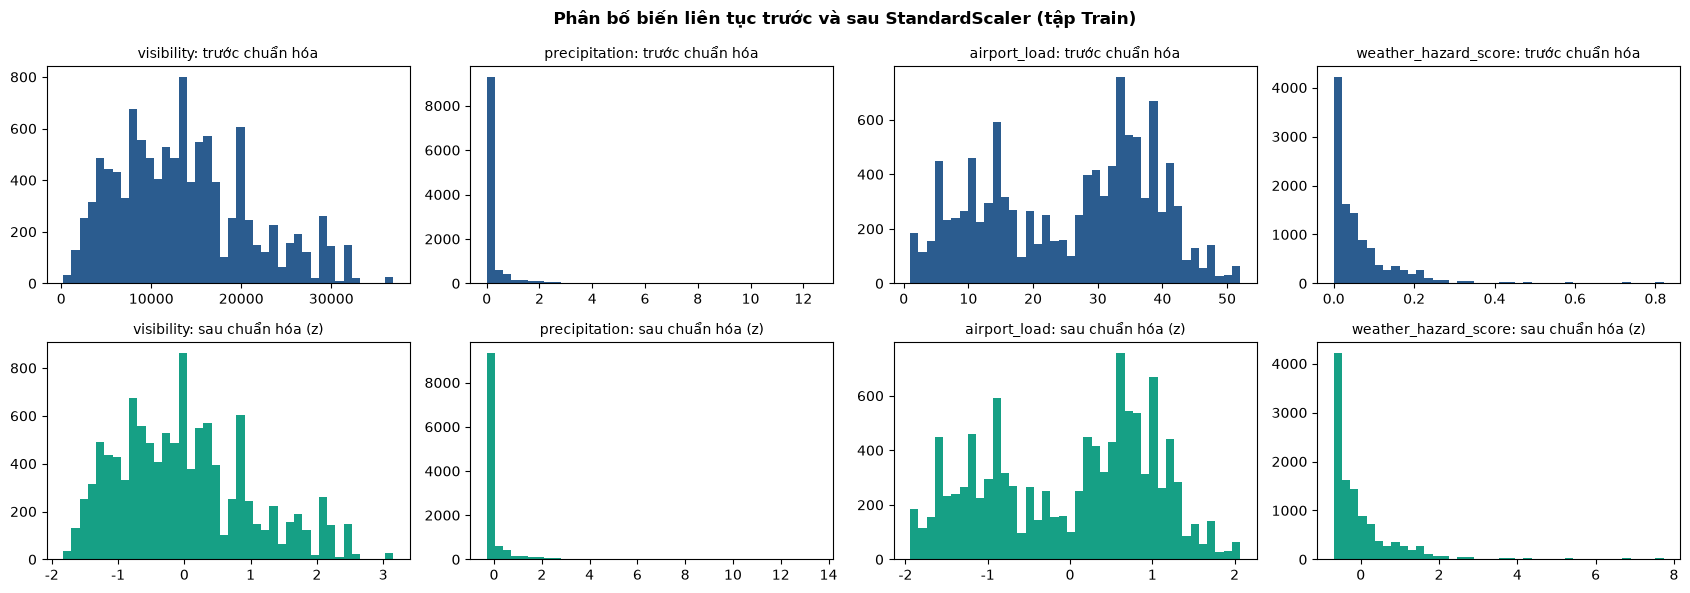

In [6]:
stat = pd.DataFrame({
    "μ Train (gốc)": pre.scaler.mean_,
    "σ Train (gốc)": pre.scaler.scale_,
    "Trung bình Train sau chuẩn hóa": X_train[NUMERIC_CONTINUOUS_COLS].mean().values,
    "Độ lệch chuẩn Train sau chuẩn hóa": X_train[NUMERIC_CONTINUOUS_COLS].std(ddof=0).values,
    "Trung bình Test sau chuẩn hóa": X_test[NUMERIC_CONTINUOUS_COLS].mean().values,
    "Độ lệch chuẩn Test sau chuẩn hóa": X_test[NUMERIC_CONTINUOUS_COLS].std(ddof=0).values,
}, index=NUMERIC_CONTINUOUS_COLS).round(4)
display(stat)

np.testing.assert_allclose(stat["Trung bình Train sau chuẩn hóa"].values, 0.0, atol=1e-6)
np.testing.assert_allclose(stat["Độ lệch chuẩn Train sau chuẩn hóa"].values, 1.0, atol=1e-6)
assert np.abs(stat["Trung bình Test sau chuẩn hóa"].values).max() > 1e-6, "Test có trung bình đúng 0: nghi ngờ đã fit trên cả Test"
print("ĐẠT: Train có trung bình 0, độ lệch chuẩn 1; Test lệch nhẹ (đúng kỳ vọng khi fit chỉ trên Train).")

show = ["visibility", "precipitation", "airport_load", "weather_hazard_score"]
fig, axes = plt.subplots(2, 4, figsize=(17, 6))
for j, c in enumerate(show):
    axes[0, j].hist(train_raw[c].dropna(), bins=40, color="#2b5c8f")
    axes[0, j].set_title(f"{c}: trước chuẩn hóa", fontsize=10)
    axes[1, j].hist(X_train[c], bins=40, color="#16a085")
    axes[1, j].set_title(f"{c}: sau chuẩn hóa (z)", fontsize=10)
plt.suptitle("Phân bố biến liên tục trước và sau StandardScaler (tập Train)", fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Cờ nhị phân giữ nguyên
14 cờ (`is_peak_hour`, `is_rain`, `is_storm`, `is_golden_triangle`, ...) vốn đã là 0/1 nên **không chuẩn hóa**: chuẩn hóa sẽ làm mất ý nghĩa "có/không" và không mang lại lợi ích.

In [7]:
b = X_train[PASSTHROUGH_BINARY_COLS]
assert set(np.unique(b.values)) <= {0.0, 1.0}
np.testing.assert_array_equal(b.values, train_raw[PASSTHROUGH_BINARY_COLS].fillna(0).astype(float).values)
display((b.mean() * 100).round(1).to_frame("% giá trị = 1 (Train)").T)
print("ĐẠT: 14 cờ nhị phân chỉ có giá trị 0/1 và giống hệt dữ liệu gốc.")

,is_peak_hour,is_heavy_traffic,is_rain,is_heavy_rain,is_high_wind,is_severe_wind,is_low_vis,is_storm,is_golden_triangle,is_holiday_flag,is_weekend_flag,is_domestic_flag,is_departure,peak_x_rain
% giá trị = 1 (Train),38.5,52.2,23.9,2.2,6.4,0.0,11.5,1.8,29.1,0.0,26.5,69.9,66.5,8.3


ĐẠT: 14 cờ nhị phân chỉ có giá trị 0/1 và giống hệt dữ liệu gốc.


## 7. Độ bền khi chạy thực tế: giá trị thiếu và danh mục lạ
**Giá trị thiếu:** điền bằng **trung vị của Train** (lưu trong metadata). Không điền 0, vì với `visibility` hay `airport_load`, số 0 nghĩa là "sương mù đặc" hay "sân bay không có chuyến", tức là biến "không có thông tin" thành một tín hiệu sai. Bảng dưới cho thấy độ lệch z-score nếu điền 0.

In [8]:
med = pre.numeric_medians_
i = {c: k for k, c in enumerate(NUMERIC_CONTINUOUS_COLS)}
cmp_fill = pd.DataFrame({
    "Trung vị Train": med.values,
    "z nếu điền trung vị (đang dùng)": [(med[c] - pre.scaler.mean_[i[c]]) / pre.scaler.scale_[i[c]] for c in NUMERIC_CONTINUOUS_COLS],
    "z nếu điền 0 (SAI)": [(0 - pre.scaler.mean_[i[c]]) / pre.scaler.scale_[i[c]] for c in NUMERIC_CONTINUOUS_COLS],
}, index=NUMERIC_CONTINUOUS_COLS).round(2)
display(cmp_fill)

# Thử nghiệm: dòng bị thiếu thời tiết và danh mục chưa từng thấy
row = test_raw.head(1).copy()
row["visibility"], row["airport_load"] = np.nan, np.nan
row["airline_code"], row["airport"] = "ZZ", "XXX"
out = pre.to_dataframe(pre.transform(row))                  # không được crash
assert not out.isna().any().any()
for col in ["airline_code", "airport"]:
    cols = [c for c in pre.encoded_cat_names if c.startswith(col + "_")]
    assert float(out[cols].sum(axis=1).iloc[0]) == 0.0
print("ĐẠT: dòng có thời tiết thiếu và hãng/sân bay lạ vẫn được biến đổi, không có NaN, danh mục lạ -> vector 0.")

,Trung vị Train,z nếu điền trung vị (đang dùng),z nếu điền 0 (SAI)
airport_load,29.00,0.26,-2.02
precipitation,0.00,-0.31,-0.31
wind_gusts_10m,18.00,-0.09,-2.56
visibility,13060.00,-0.08,-1.86
weather_hazard_score,0.04,-0.31,-0.69
load_x_weather,0.69,-0.35,-0.62
hour_sin,-0.44,-0.31,0.33
hour_cos,-0.44,-0.24,0.48
dow_sin,0.00,0.06,0.06
dow_cos,-0.22,-0.07,0.25


ĐẠT: dòng có thời tiết thiếu và hãng/sân bay lạ vẫn được biến đổi, không có NaN, danh mục lạ -> vector 0.


## 8. Lưu artifact và kiểm tra nạp lại
Ba tệp được lưu vào `data/processed/` để Thành viên 5 (huấn luyện) và Thành viên 6 (web, hàm `predict_risk()`) dùng chung. Chỉ dùng đối tượng chuẩn scikit-learn (không có lớp tự định nghĩa trong pickle), nên nạp được ở nơi không có mã của dự án.

> **Phiên bản scikit-learn:** artifact gắn với phiên bản đã tạo ra nó (ghi trong metadata). Cả nhóm cần cài **cùng một phiên bản** (ghim trong `requirements-ml.txt`); nếu khác, `load()` sẽ cảnh báo.

In [9]:
if SAVE_ARTIFACTS:
    pre.save(PROCESSED_DIR, extra_meta={
        "cutoff_date": cutoff, "train_rows": len(train_raw), "test_rows": len(test_raw),
        "total_features": len(pre.feature_names), "one_hot_columns": pre.encoded_cat_names,
    })
    print("Đã ghi artifact vào", PROCESSED_DIR)

files = [PROCESSED_DIR / n for n in ["encoder.joblib", "scaler.joblib", "preprocessing_metadata.json"]]
display(pd.DataFrame({"Tệp": [f.name for f in files], "Tồn tại": [f.exists() for f in files],
                      "Dung lượng (KB)": [round(f.stat().st_size / 1024, 1) if f.exists() else None for f in files]}))
assert all(f.exists() for f in files), "Thiếu artifact: đặt SAVE_ARTIFACTS = True"

junk = PROCESSED_DIR / "preprocessor.joblib"
if junk.exists():
    print(f"Lưu ý: {junk.name} ({junk.stat().st_size} byte) không thuộc danh sách artifact và không được sinh ra bởi mã hiện tại; nên xóa.")

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    loaded = FlightDataPreprocessor.load(PROCESSED_DIR)
    for x in w:
        print("CẢNH BÁO:", x.message)
np.testing.assert_allclose(loaded.transform(test_raw), pre.transform(test_raw))
assert loaded.feature_names == pre.feature_names
meta = json.loads((PROCESSED_DIR / "preprocessing_metadata.json").read_text(encoding="utf-8"))
assert len(set(meta["feature_names"])) == len(meta["feature_names"]) == X_train.shape[1]
print(f"ĐẠT: nạp lại cho kết quả giống hệt; metadata có {len(meta['feature_names'])} đặc trưng không trùng tên.")
print("Phiên bản scikit-learn ghi trong metadata:", meta.get("sklearn_version"), "| đang dùng:", sklearn.__version__)

Đã ghi artifact vào C:\Users\LENOVO\Documents\ScrapeData\data\processed


,Tệp,Tồn tại,Dung lượng (KB)
0,encoder.joblib,True,2.0
1,scaler.joblib,True,1.2
2,preprocessing_metadata.json,True,5.6


Lưu ý: preprocessor.joblib (2 byte) không thuộc danh sách artifact và không được sinh ra bởi mã hiện tại; nên xóa.
ĐẠT: nạp lại cho kết quả giống hệt; metadata có 64 đặc trưng không trùng tên.
Phiên bản scikit-learn ghi trong metadata: 1.9.1 | đang dùng: 1.9.1


## 9. Tổng kết và nội dung cho báo cáo (Chương 4, Mục 4.1)

**Đã hoàn thành**
- Ma trận X không chứa cột rò rỉ (kiểm định bằng xáo trộn); bộ tiền xử lý **chỉ fit trên Train** (chia theo thời gian).
- One-Hot (`handle_unknown="ignore"`) cho 5 biến phân loại; StandardScaler cho 10 biến liên tục; giữ nguyên 14 cờ nhị phân.
- Giá trị thiếu điền bằng trung vị Train; danh mục lạ không làm crash.
- Artifact `encoder.joblib`, `scaler.joblib`, `preprocessing_metadata.json` nạp lại cho kết quả giống hệt.

**Ý chính cho báo cáo:** bảng so sánh số danh mục trước/sau One-Hot (mục 4), công thức $z=(x-\mu)/\sigma$ và bảng μ, σ (mục 5), lý do `handle_unknown="ignore"`, lý do fit chỉ trên Train và điền thiếu bằng trung vị (mục 7).

**Hạn chế cần nêu**
1. `airport` có nhiều danh mục hiếm; có thể gộp thành `OTHER` nếu cần.
2. Trung vị Train chỉ phản ánh giai đoạn thu thập ngắn; cần fit lại khi có thêm dữ liệu.
3. Mốc cắt Train/Test là giữa ngày; Test chỉ có một khoảng thời gian ngắn nên chưa đại diện cho mùa khác.
4. Tệp `train.csv`/`test.csv` do `build_and_save_encoded_dataset()` sinh ra còn cột `delay_min` (chỉ dành cho hồi quy); Thành viên 5 không được đưa nó vào X.

**Bàn giao:** Thành viên 5 dùng `FlightDataPreprocessor.load()` hoặc `train.csv`/`test.csv`; Thành viên 6 dùng cùng `load()` trong `predict_risk()`.